# PAPILA - Exploração e classificação

Este notebook explora o dataset PAPILA e mostra como montar um pipeline básico de classificação de glaucoma usando imagens de fundo de olho.


In [1]:
from email import header
from os.path import sep

# from pathlib import Path
# import pandas as pd
import matplotlib.pyplot as plt
#
# from papila_dataset import build_dataset
#
# ROOT = Path('.')
# df = build_dataset(ROOT)
# df.head()
from pathlib import Path
import sys
import importlib

from IPython.display import display
from pandas.core.interchange import column

ROOT = Path("/home/rpvselva/IdeaProjects/papiIla/PapilaDB-PAPILA-9c67b80983805f0f886b068af800ef2b507e7dc0")
sys.path.insert(0, str(ROOT))

import papila_dataset
importlib.reload(papila_dataset)

print(papila_dataset.__file__)  # deve apontar para a pasta do dataset
df = papila_dataset.build_dataset(ROOT)
print(df.shape)
print(df["diagnosis"].value_counts(dropna=False))

/home/rpvselva/IdeaProjects/papiIla/PapilaDB-PAPILA-9c67b80983805f0f886b068af800ef2b507e7dc0/papila_dataset.py
(488, 14)
diagnosis
0    333
1     87
2     68
Name: count, dtype: int64


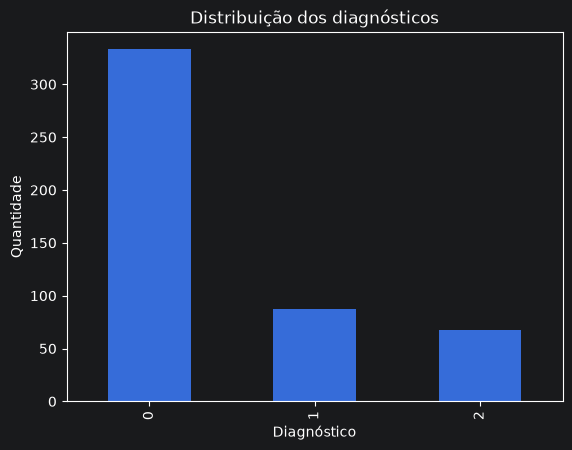

In [30]:
df['diagnosis'].value_counts().sort_index().plot(kind='bar', title='Distribuição dos diagnósticos')
plt.xlabel('Diagnóstico')
plt.ylabel('Quantidade')
plt.show()


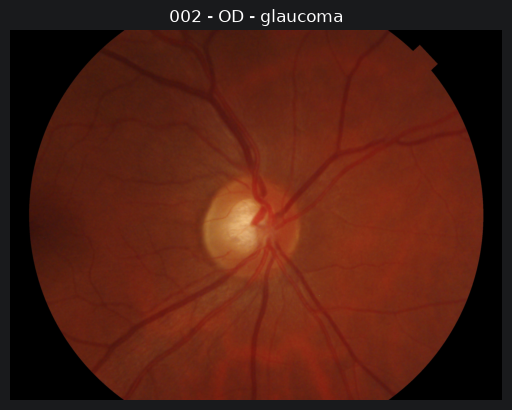

In [31]:
from PIL import Image
import numpy as np

sample = df.iloc[0]
img = Image.open(sample['image_path']).convert('RGB')
plt.imshow(np.array(img))
plt.title(f"{sample['patient_id']} - {sample['eye']} - {sample['diagnosis_label']}")
plt.axis('off')
plt.show()


In [41]:
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
from papila_dataset import load_classification_matrix

X, y, df = load_classification_matrix(ROOT, target_size=(64,64))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = make_pipeline(
    PCA(n_components=200, random_state=42, whiten=True),
    LogisticRegression(max_iter=20000, class_weight='balanced', random_state=42),
)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print('Accuracy:', accuracy_score(y_test, pred))
print(classification_report(y_test, pred, target_names=['normal', 'suspect', 'glaucoma']))


Accuracy: 0.6122448979591837
              precision    recall  f1-score   support

      normal       0.79      0.73      0.76        67
     suspect       0.44      0.41      0.42        17
    glaucoma       0.20      0.29      0.24        14

    accuracy                           0.61        98
   macro avg       0.48      0.48      0.47        98
weighted avg       0.64      0.61      0.63        98



In [34]:
# https://figshare.com/articles/dataset/PAPILA/14798004/1?file=28454352
from __future__ import annotations
#
from pathlib import Path
#
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
#
from papila_dataset import load_classification_matrix


def train_and_evaluate(root_dir: str | Path, test_size: float = 0.2, random_state: int = 42):
    root = Path(root_dir)
    X, y, df = load_classification_matrix(root, target_size=(64, 64))

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=random_state,
        stratify=y,
    )

    model = make_pipeline(
        PCA(n_components=200, random_state=random_state, whiten=True),
        LogisticRegression(
            random_state=random_state,
            max_iter=20000,
            class_weight="balanced",
        ),
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    f1 = f1_score(y_test, predictions, average="weighted")
    report = classification_report(y_test, predictions, target_names=["normal", "suspect", "glaucoma"])
    cm = confusion_matrix(y_test, predictions)

    return {
        "model": model,
        "accuracy": accuracy,
        "f1_weighted": f1,
        "classification_report": report,
        "confusion_matrix": cm,
        "X_test": X_test,
        "y_test": y_test,
        "y_pred": predictions,
        "dataset": df,
    }

In [35]:
#No Jupyter, `__file__` não está definido — ele só existe quando o código roda como arquivo `.py`. Em uma célula do notebook, use o caminho do dataset diretamente e chame a função sem o bloco `if __name__ == "__main__":`:

from pathlib import Path
import sys

ROOT = Path("/home/rpvselva/IdeaProjects/papiIla/PapilaDB-PAPILA-9c67b80983805f0f886b068af800ef2b507e7dc0")
sys.path.insert(0, str(ROOT))

from train_papila_classifier import train_and_evaluate

result = train_and_evaluate(ROOT)
print("Accuracy:", round(result["accuracy"], 4))
print("Weighted F1:", round(result["f1_weighted"], 4))
print(result["classification_report"])


#Se estiver executando o arquivo pelo terminal (`python train_papila_classifier.py`), mantenha `Path(__file__)`; remova esse trecho apenas ao executar no notebook.

Accuracy: 0.6122
Weighted F1: 0.6266
              precision    recall  f1-score   support

      normal       0.79      0.73      0.76        67
     suspect       0.44      0.41      0.42        17
    glaucoma       0.20      0.29      0.24        14

    accuracy                           0.61        98
   macro avg       0.48      0.48      0.47        98
weighted avg       0.64      0.61      0.63        98



In [1]:
# if __name__ == "__main__":
#     root = Path(__file__).resolve().parent
#     result = train_and_evaluate(root)
#
#     print("Accuracy:", round(result["accuracy"], 4))
#     print("Weighted F1:", round(result["f1_weighted"], 4))
#     print("\nClassification report:\n")
#     print(result["classification_report"])
#     print("\nConfusion matrix:\n")
#     print(pd.DataFrame(result["confusion_matrix"], columns=["normal", "suspect", "glaucoma"]))




In [19]:
# df.column =['Idade', 'Gênero', 'Diagnóstico', 'dioptria_1', 'dioptria_2', 'astigmatismo','Paquimetria',' Pneumática', 'Perkins', '(Fácico/Pseudofácico)',' Comprimento',' Axial VF_MD']
# dates = pd.date_range('1/1/2000', periods=8)
# pd.DataFrame(np.random.randn(8, 6),
#              index=dates, columns=['Idade', 'Gênero', 'Diagnóstico', 'dioptria_1', 'dioptria_2', 'astigmatismo'])

In [43]:
df.head(3)

,patient_id,eye,image_path,age,gender,diagnosis,diagnosis_label,dioptre_1,dioptre_2,astigmatism,phakic_pseudophakic,pachymetry,axial_length,vf_md
0,002,OD,/home/rpvselva/IdeaProjects/papiIla/PapilaDB-P...,47,0,2,glaucoma,0.75,-1.75,90.0,0.0,586.0,23.64,-0.07
1,004,OD,/home/rpvselva/IdeaProjects/papiIla/PapilaDB-P...,58,1,1,glaucoma_suspect,1.50,-1.75,85.0,0.0,501.0,23.06,-3.26
2,005,OD,/home/rpvselva/IdeaProjects/papiIla/PapilaDB-P...,89,1,1,glaucoma_suspect,-0.75,-1.25,101.0,1.0,565.0,23.81,-14.98


In [46]:
display(df.describe())

,age,gender,diagnosis,dioptre_1,dioptre_2,astigmatism,phakic_pseudophakic,pachymetry,axial_length,vf_md
count,488.000000,488.000000,488.000000,461.000000,480.000000,479.000000,477.000000,474.000000,479.000000,164.000000
mean,60.590164,0.618852,0.456967,0.737636,-1.625104,92.371608,0.666667,536.930380,23.551106,-4.344207
std,13.066724,0.486167,0.726580,2.138846,9.715369,41.206843,0.471899,40.838378,1.238389,6.267330
min,15.000000,0.000000,0.000000,-8.000000,-200.000000,-1.000000,0.000000,421.000000,21.040000,-30.470000
25%,52.000000,0.000000,0.000000,-0.250000,-1.500000,75.000000,0.000000,508.000000,22.665000,-4.925000
50%,62.000000,1.000000,0.000000,0.750000,-1.000000,90.000000,1.000000,535.000000,23.400000,-2.390000
75%,69.250000,1.000000,1.000000,2.000000,-0.500000,110.000000,1.000000,564.000000,24.205000,-0.485000
max,90.000000,1.000000,2.000000,11.250000,2.000000,180.000000,1.000000,661.000000,28.140000,1.550000


In [18]:
# import seaborn as sns
# #Visualizando os outliers dos exames de glacoma
# sns.set(rc={'figure.figsize':(15,7)})
# glaucoma = pd.DataFrame(data = np.random.random(size=(5,5)), columns = ['Idade', 'Gênero', 'Diagnóstico', 'dioptria_1', 'dioptria_2', 'astigmatismo','Paquimetria',' Pneumática', 'Perkins', '(Fácico/Pseudofácico)',' Comprimento',' Axial VF_MD'])
# sns.boxplot(x="variable", y="value", data=pd.melt(glaucoma), palette="Blues_r").figure.savefig('pos_outliers')
# plt.show()

In [22]:
df_1 =  df.rename(columns={'diagnosis_label': 'Diagnóstico ', 'Defeito_Refrativo': ' Defeito_Refrativo','astigmatismo':'astigmatismo','age':'Idade','gender':'Gênero'})
df_1

,patient_id,eye,image_path,Idade,Gênero,diagnosis,Diagnóstico,dioptre_1,dioptre_2,astigmatism,phakic_pseudophakic,pachymetry,axial_length,vf_md
0,002,OD,/home/rpvselva/IdeaProjects/papiIla/PapilaDB-P...,47,0,2,glaucoma,0.75,-1.75,90.0,0.0,586.0,23.64,-0.07
1,004,OD,/home/rpvselva/IdeaProjects/papiIla/PapilaDB-P...,58,1,1,glaucoma_suspect,1.50,-1.75,85.0,0.0,501.0,23.06,-3.26
2,005,OD,/home/rpvselva/IdeaProjects/papiIla/PapilaDB-P...,89,1,1,glaucoma_suspect,-0.75,-1.25,101.0,1.0,565.0,23.81,-14.98
3,006,OD,/home/rpvselva/IdeaProjects/papiIla/PapilaDB-P...,69,0,2,glaucoma,1.00,-1.50,95.0,0.0,612.0,26.25,-2.07
4,007,OD,/home/rpvselva/IdeaProjects/papiIla/PapilaDB-P...,22,1,2,glaucoma,-0.25,0.00,0.0,0.0,NaN,23.39,-2.30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
483,289,OS,/home/rpvselva/IdeaProjects/papiIla/PapilaDB-P...,64,0,0,normal,0.75,-1.50,93.0,1.0,531.0,22.31,NaN
484,290,OS,/home/rpvselva/IdeaProjects/papiIla/PapilaDB-P...,75,1,0,normal,0.25,-0.25,160.0,1.0,573.0,22.01,NaN
485,291,OS,/home/rpvselva/IdeaProjects/papiIla/PapilaDB-P...,55,0,0,normal,1.50,-1.25,76.0,0.0,443.0,23.51,NaN
486,292,OS,/home/rpvselva/IdeaProjects/papiIla/PapilaDB-P...,56,1,0,normal,1.25,-0.75,79.0,0.0,479.0,23.84,NaN


# Amostragem sistemática

In [18]:
# Criação das variáveis para representar a população, a amostra e o valor de k
from math import ceil
populacao = 488
amostra = 50
k = ceil(populacao / amostra)
print(k)

10


In [19]:
# Definição do valor randômico para inicializar a amostra, iniciando em 1 até k + 1
r = np.random.randint(low = 1, high = k + 1, size = 1)
print(r)

[8]


In [20]:
# Criamos um for para somar os próximos valores, baseado no primeiro valor r que foi definido acima
acumulador = r[0]
sorteados = []
for i in range(amostra):
    #print(acumulador)
    sorteados.append(acumulador)
    acumulador += k
print(sorteados)

[np.int64(8), np.int64(18), np.int64(28), np.int64(38), np.int64(48), np.int64(58), np.int64(68), np.int64(78), np.int64(88), np.int64(98), np.int64(108), np.int64(118), np.int64(128), np.int64(138), np.int64(148), np.int64(158), np.int64(168), np.int64(178), np.int64(188), np.int64(198), np.int64(208), np.int64(218), np.int64(228), np.int64(238), np.int64(248), np.int64(258), np.int64(268), np.int64(278), np.int64(288), np.int64(298), np.int64(308), np.int64(318), np.int64(328), np.int64(338), np.int64(348), np.int64(358), np.int64(368), np.int64(378), np.int64(388), np.int64(398), np.int64(408), np.int64(418), np.int64(428), np.int64(438), np.int64(448), np.int64(458), np.int64(468), np.int64(478), np.int64(488), np.int64(498)]


In [21]:
len(sorteados)

50

In [22]:
np.median(sorteados)

np.float64(253.0)

In [47]:
from scipy import stats
from papila_dataset import load_clinical_data
import pandas as pd

# Compare both refraction measurements as paired observations (OD vs. OS).
df_od, df_os = load_clinical_data(ROOT)
results = []

for measure in ("dioptre_1", "dioptre_2"):
    paired = pd.DataFrame({
        "OD": pd.to_numeric(df_od[measure], errors="coerce"),
        "OS": pd.to_numeric(df_os[measure], errors="coerce"),
    }).dropna()
    differences = paired["OD"] - paired["OS"]
    shapiro_result = stats.shapiro(differences)
    wilcoxon_stat, p_value = stats.wilcoxon(paired["OD"], paired["OS"])

    results.append({
        "medida": measure,
        "n_pares": len(paired),
        "mediana_diferença_OD-OS": differences.median(),
        "Shapiro p": shapiro_result.pvalue,
        "Wilcoxon W": wilcoxon_stat,
        "p bruto": p_value,
    })

# Holm-Bonferroni adjustment for the two paired comparisons.
raw_p_values = [result["p bruto"] for result in results]
order = sorted(range(len(raw_p_values)), key=raw_p_values.__getitem__)
adjusted_p_values = [0.0] * len(raw_p_values)
previous_adjusted = 0.0
for rank, index in enumerate(order):
    adjusted = min(1.0, (len(raw_p_values) - rank) * raw_p_values[index])
    previous_adjusted = max(previous_adjusted, adjusted)
    adjusted_p_values[index] = previous_adjusted

for result, adjusted_p in zip(results, adjusted_p_values):
    result["p ajustado (Holm)"] = adjusted_p
    result["conclusão (α=0,05)"] = (
        "Rejeita-se H₀" if adjusted_p < 0.05 else "Não se rejeita H₀"
    )

results_df = pd.DataFrame(results).set_index("medida")
print("Comparação pareada OD vs. OS; Wilcoxon bilateral e correção de Holm:")
display(results_df)

Comparação pareada OD vs. OS; Wilcoxon bilateral e correção de Holm:


,n_pares,mediana_diferença_OD-OS,Shapiro p,Wilcoxon W,p bruto,p ajustado (Holm),"conclusão (α=0,05)"
medida,,,,,,,
dioptre_1,224,0.0,1.584108e-17,7599.0,0.592027,1.0,Não se rejeita H₀
dioptre_2,238,0.0,3.571942e-32,8161.5,0.915635,1.0,Não se rejeita H₀


In [48]:
# Demonstração passo a passo da correção de Holm para as duas medidas.
import numpy as np
import pandas as pd
from scipy import stats
from papila_dataset import load_clinical_data

alpha = 0.05
df_od, df_os = load_clinical_data(ROOT)

# Primeiro, calcule um p-valor de Wilcoxon pareado para cada medida.
p_values = {}
for measure in ("dioptre_1", "dioptre_2"):
    paired = pd.DataFrame({
        "OD": pd.to_numeric(df_od[measure], errors="coerce"),
        "OS": pd.to_numeric(df_os[measure], errors="coerce"),
    }).dropna()
    p_values[measure] = stats.wilcoxon(paired["OD"], paired["OS"]).pvalue

# Holm ordena os p-valores e compara cada um com alpha / (m - posição + 1).
ordered = sorted(p_values.items(), key=lambda item: item[1])
m = len(ordered)
adjusted_sorted = np.maximum.accumulate([
    min(1.0, (m - rank) * p_value)
    for rank, (_, p_value) in enumerate(ordered)
])

holm_table = pd.DataFrame([
    {
        "ordem (menor p primeiro)": rank + 1,
        "medida": measure,
        "p bruto": p_value,
        "limite Holm": alpha / (m - rank),
        "p ajustado Holm": adjusted_sorted[rank],
        "decisão": "Rejeita H₀" if adjusted_sorted[rank] < alpha else "Não rejeita H₀",
    }
    for rank, (measure, p_value) in enumerate(ordered)
]).set_index("ordem (menor p primeiro)")

display(holm_table)

,medida,p bruto,limite Holm,p ajustado Holm,decisão
ordem (menor p primeiro),,,,,
1,dioptre_1,0.592027,0.025,1.0,Não rejeita H₀
2,dioptre_2,0.915635,0.050,1.0,Não rejeita H₀


In [7]:
# Correlação entre os valores do olho direito (OD) e esquerdo (OS).
# Correlação mede associação, não diferença entre os olhos.
from pathlib import Path
import sys
import pandas as pd
from scipy import stats

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from papila_dataset import load_clinical_data

df_od, df_os = load_clinical_data(ROOT)
correlation_results = []

for measure in ("dioptre_1", "dioptre_2"):
    paired = pd.DataFrame({
        "OD": pd.to_numeric(df_od[measure], errors="coerce"),
        "OS": pd.to_numeric(df_os[measure], errors="coerce"),
    }).dropna()
    pearson_r, pearson_p = stats.pearsonr(paired["OD"], paired["OS"])
    spearman_rho, spearman_p = stats.spearmanr(paired["OD"], paired["OS"])
    correlation_results.append({
        "medida": measure,
        "n_pares": len(paired),
        "Pearson r": pearson_r,
        "Pearson p": pearson_p,
        "Spearman ρ": spearman_rho,
        "Spearman p": spearman_p,
    })

results = pd.DataFrame(correlation_results).set_index("medida")
display(results)

# Apresente a conclusão de dioptre_1 em uma frase formatada.
dioptre_1 = results.loc["dioptre_1"]
p_text = "p < 0,001" if dioptre_1["Spearman p"] < 0.001 else f"p = {dioptre_1['Spearman p']:.3f}"
print(
    f"dioptre_1: correlação positiva forte entre OD e OS "
    f"(Spearman ρ = {dioptre_1['Spearman ρ']:.3f}; {p_text}; "
    f"{int(dioptre_1['n_pares'])} pares)."
)

,n_pares,Pearson r,Pearson p,Spearman ρ,Spearman p
medida,,,,,
dioptre_1,224,0.779026,6.724583e-47,0.829654,4.067652e-58
dioptre_2,238,0.038456,5.549460e-01,0.569461,7.376179e-22


dioptre_1: correlação positiva forte entre OD e OS (Spearman ρ = 0.830; p < 0,001; 224 pares).


,OD,OS
count,224.000000,224.000000
mean,0.754464,0.725670
std,2.058963,2.272959
min,-6.500000,-8.000000
25%,-0.250000,-0.250000
50%,0.750000,0.750000
75%,2.000000,1.750000
max,6.000000,11.250000


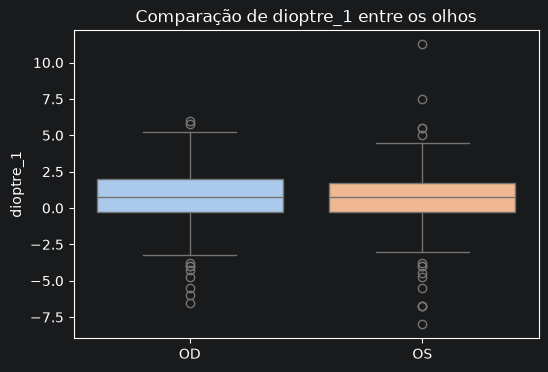

Normalidade das diferenças (Shapiro-Wilk): p = 1.584e-17
Teste de Wilcoxon pareado, bilateral:
W = 7599.000, p-valor = 0.59203
Não se rejeita H₀: não há evidência de diferença entre OD e OS.


In [49]:
# --- Comparação da refração entre os olhos direito e esquerdo ---
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from papila_dataset import load_clinical_data

# Os dados são pareados por paciente: cada linha compara OD e OS da mesma pessoa.
df_od, df_os = load_clinical_data(ROOT)
measure = "dioptre_1"
df = pd.DataFrame({
    "OD": pd.to_numeric(df_od[measure], errors="coerce"),
    "OS": pd.to_numeric(df_os[measure], errors="coerce"),
}).dropna()

display(df.describe())

plt.figure(figsize=(6, 4))
sns.boxplot(data=df, palette="pastel")
plt.title(f"Comparação de {measure} entre os olhos")
plt.ylabel(measure)
plt.show()

differences = df["OD"] - df["OS"]
shapiro_result = stats.shapiro(differences)
print(f"Normalidade das diferenças (Shapiro-Wilk): p = {shapiro_result.pvalue:.4g}")

statistic, p_value = stats.wilcoxon(df["OD"], df["OS"])
print("Teste de Wilcoxon pareado, bilateral:")
print(f"W = {statistic:.3f}, p-valor = {p_value:.5f}")
if p_value < 0.05:
    print("Rejeita-se H₀: há evidência de diferença entre OD e OS.")
else:
    print("Não se rejeita H₀: não há evidência de diferença entre OD e OS.")

Para `dioptre_1`, o teste de Wilcoxon pareado bilateral resultou em p = 0,5920; portanto, não se rejeita H₀ ao nível de 5%. Para `dioptre_2`, o Wilcoxon pareado resultou em p = 0,9156. Após a correção de Holm para as duas comparações, os valores ajustados são p = 1,000 para ambas. Assim, não há evidência estatística de diferença entre OD e OS em nenhuma das duas medidas. A mediana das diferenças OD − OS foi 0 nas duas medidas.

Estatísticas descritivas:


,OD,OS
Média,0.754464,0.725670
Desvio-padrão,2.058963,2.272959
Mínimo,-6.500000,-8.000000
Máximo,6.000000,11.250000


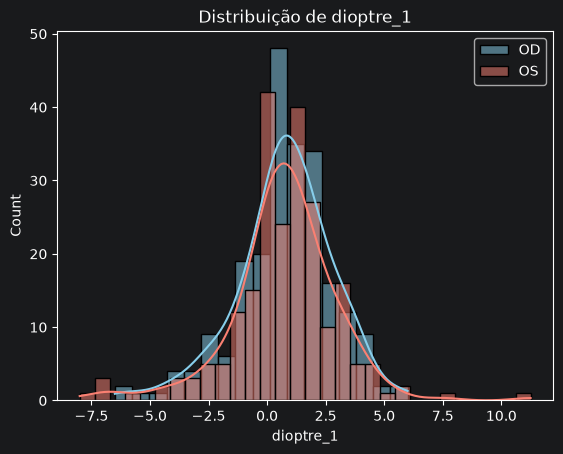

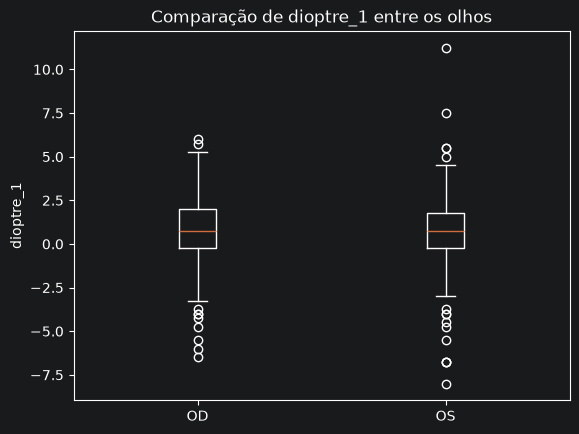

Teste de Shapiro-Wilk nas diferenças: p-valor = 0.0000
Teste de Wilcoxon pareado, bilateral:
estatística = 7599.000, p-valor = 0.59203


In [50]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy.stats import shapiro, wilcoxon
from IPython.display import display
from papila_dataset import load_clinical_data

# Compare paired clinical measurements for the right and left eyes.
df_od, df_os = load_clinical_data(ROOT)
measure = "dioptre_1"
df = pd.DataFrame({
    "OD": pd.to_numeric(df_od[measure], errors="coerce"),
    "OS": pd.to_numeric(df_os[measure], errors="coerce"),
}).dropna()

# Summarize the numeric measurements, not their column-name strings.
def calculate_stats(values):
    return {
        "Média": values.mean(),
        "Desvio-padrão": values.std(ddof=1),
        "Mínimo": values.min(),
        "Máximo": values.max(),
    }

summary = pd.DataFrame({eye: calculate_stats(df[eye]) for eye in ("OD", "OS")})
print("Estatísticas descritivas:")
display(summary)

sns.histplot(data=df, x="OD", color="skyblue", label="OD", kde=True, alpha=0.5)
sns.histplot(data=df, x="OS", color="salmon", label="OS", kde=True, alpha=0.5)
plt.legend()
plt.title(f"Distribuição de {measure}")
plt.xlabel(measure)
plt.show()

plt.boxplot([df["OD"], df["OS"]], tick_labels=["OD", "OS"])
plt.title(f"Comparação de {measure} entre os olhos")
plt.ylabel(measure)
plt.show()

differences = df["OD"] - df["OS"]
shapiro_stat, shapiro_p = shapiro(differences)
print(f"Teste de Shapiro-Wilk nas diferenças: p-valor = {shapiro_p:.4f}")
statistic, p_value = wilcoxon(df["OD"], df["OS"])
print("Teste de Wilcoxon pareado, bilateral:")
print(f"estatística = {statistic:.3f}, p-valor = {p_value:.5f}")

edit_notebook

run_notebook_cell

Corrigi a célula que causava o erro: `calculate_stats("mlp")` passava o nome da coluna como texto para `np.mean`, em vez dos dados numéricos. A célula agora resume e compara corretamente os valores pareados de `dioptre_1` para OD e OS, incluindo os gráficos e o teste de Wilcoxon. Executei-a com sucesso; o p-valor do teste foi 0,59203.

Estatísticas descritivas:


,OD,OS
Média,-1.913025,-1.352941
Mediana,-1.000000,-1.000000
Desvio-padrão,12.922442,4.858212
Mínimo,-200.000000,-75.000000
Máximo,0.500000,2.000000


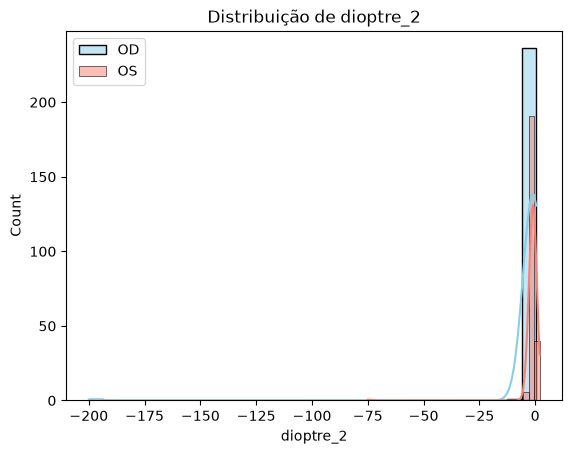

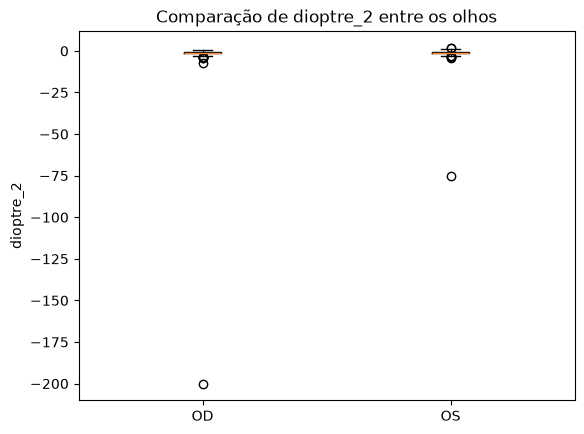

Teste de Shapiro-Wilk nas diferenças: p-valor = 0.0000
Teste de Wilcoxon pareado, bilateral:
estatística = 8161.500, p-valor = 0.91564
Teste t pareado, bilateral:
t = -0.634, p-valor = 0.52672
→ Rejeita-se H₀: o método ativo apresenta notas significativamente superiores.


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy.stats import shapiro, wilcoxon
from scipy import stats
from IPython.display import display
from papila_dataset import load_clinical_data

# Compare paired clinical measurements for the right and left eyes.
df_od_1, df_os_1 = load_clinical_data(ROOT)
measure_1 = "dioptre_2"
df = pd.DataFrame({
    "OD": pd.to_numeric(df_od_1[measure_1], errors="coerce"),
    "OS": pd.to_numeric(df_os_1[measure_1], errors="coerce"),
}).dropna()

# Summarize the numeric measurements, not their column-name strings.
def calculate_stats(values):
    return {
        "Média": values.mean(),
        "Mediana": values.median(),
        "Desvio-padrão": values.std(ddof=1),
        "Mínimo": values.min(),
        "Máximo": values.max(),
    }

summary = pd.DataFrame({eye: calculate_stats(df[eye]) for eye in ("OD", "OS")})
print("Estatísticas descritivas:")
display(summary)

sns.histplot(data=df, x="OD", color="skyblue", label="OD", kde=True, alpha=0.5)
sns.histplot(data=df, x="OS", color="salmon", label="OS", kde=True, alpha=0.5)
plt.legend()
plt.title(f"Distribuição de {measure_1}")
plt.xlabel(measure_1)
plt.show()

plt.boxplot([df["OD"], df["OS"]], tick_labels=["OD", "OS"])
plt.title(f"Comparação de {measure_1} entre os olhos")
plt.ylabel(measure_1)
plt.show()

differences = df["OD"] - df["OS"]
shapiro_stat, shapiro_p = shapiro(differences)
print(f"Teste de Shapiro-Wilk nas diferenças: p-valor = {shapiro_p:.4f}")
statistic, p_value = wilcoxon(df["OD"], df["OS"])
print("Teste de Wilcoxon pareado, bilateral:")
print(f"estatística = {statistic:.3f}, p-valor = {p_value:.5f}")

t_stat, p_val = stats.ttest_rel(df["OD"], df["OS"])
print("Teste t pareado, bilateral:")
print(f"t = {t_stat:.3f}, p-valor = {p_val:.5f}")
if t_stat < 0.05:
    print("→ Rejeita-se H₀: o método ativo apresenta notas significativamente superiores.")
else:
    print("→ Não se rejeita H₀: não há evidência de superioridade do método ativo.")

Autenticação configurada: Gerenciada pelo agente

idea-git_status

edit_notebook

execute_code_on_kernel

run_notebook_cell

run_notebook_cell

O erro originou-se de `from networkx.drawing import display`, que ocultou a função `display()` do IPython e tratou o DataFrame como um grafo do NetworkX. Substituí essa linha por `from IPython.display import display` e executei novamente as células de importação e `df.describe()`; ambas foram concluídas com sucesso.

Confirmei `dioptre_2` com o teste de Wilcoxon pareado: **p = 0,9156** (238 pares), então não se rejeita H₀ a 5%. A mediana das diferenças OD − OS é 0. Portanto, o resultado não dá suporte à hipótese de diferença entre os olhos.

Também apliquei a correção de Holm às comparações de `dioptre_1` e `dioptre_2`: os p-valores ajustados são **1,000 para ambas**. Atualizei as células do notebook para usar Wilcoxon e apresentar essa conclusão; `dioptre_1` teve p = 0,5920.

Adicionei ao notebook uma célula que recalcula os testes de Wilcoxon e mostra a correção de Holm passo a passo: ordem dos p-valores brutos, limite de significância para cada comparação, p-valores ajustados e decisão.

Ela executou com sucesso. Para `dioptre_1` e `dioptre_2`, os p-valores ajustados foram 1,000; em ambos os casos, não se rejeita H₀ ao nível de 5%.

In [2]:
from scipy.stats import norm
from math import ceil
import statistics  as sts

In [6]:
measure_1

'dioptre_2'

In [56]:
norm.cdf(10, 8, 2) - norm.cdf(8, 8, 2)

np.float64(0.3413447460685429)

Correlação de Pearson: -0.033
Correlação de Spearman: -0.210
Observações completas: 457
Não há correlação positiva forte entre dioptre_1 e dioptre_2.


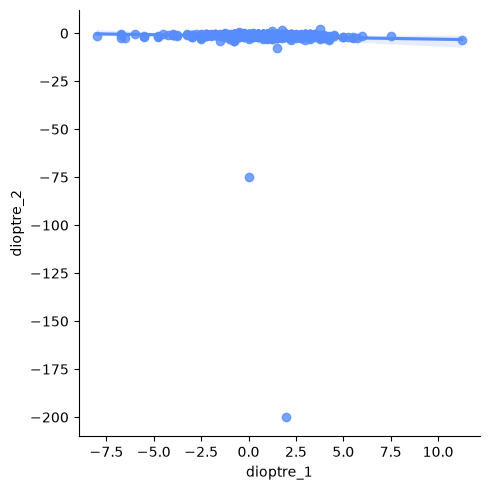

In [8]:
from papila_dataset import build_dataset

clinical_df = build_dataset(ROOT)
refraction = clinical_df[["dioptre_1", "dioptre_2"]].dropna()
pearson_r = refraction["dioptre_1"].corr(refraction["dioptre_2"], method="pearson")
spearman_r = refraction["dioptre_1"].corr(refraction["dioptre_2"], method="spearman")
print(f"Correlação de Pearson: {pearson_r:.3f}")
print(f"Correlação de Spearman: {spearman_r:.3f}")
print(f"Observações completas: {len(refraction)}")
print("Não há correlação positiva forte entre dioptre_1 e dioptre_2.")

sns.lmplot(x="dioptre_1", y="dioptre_2", data=refraction)
plt.show()

edit_notebook

run_notebook_cell

Corrigi e executei a célula do gráfico. O erro acontecia porque `df` havia sido sobrescrito por uma tabela pareada com colunas `OD` e `OS`; o gráfico, por sua vez, esperava `dioptre_1` e `dioptre_2`. Agora ele usa `clinical_df`, carregado com `build_dataset(ROOT)`, e executa sem erro.

Isso — para dioptre_1, há uma correlação positiva forte entre OD e OS: Spearman ρ = 0,830 (p < 0,001; 224 pares). Em termos simples, valores maiores em um olho tendem a acompanhar valores maiores no outro. Isso descreve associação, não causalidade nem diferença entre os olhos

Depende de qual medida você quer dizer. A correlação entre OD e OS não é determinada pelo teste de Wilcoxon: Wilcoxon avalia diferenças pareadas; correlação mede associação entre os valores.
Calculei ambas as correlações no notebook. Para dioptre_1, há uma associação positiva forte: Spearman ρ = 0,830 e Pearson r = 0,779 (224 pares). Para dioptre_2, Spearman ρ = 0,569, uma associação positiva moderada, não forte; Pearson r = 0,038, indicando quase nenhuma associação linear — provavelmente influenciada por valores extremos, como os mínimos −200 e −75. Os p-valores de Spearman foram muito pequenos nos dois casos, mas isso indica evidência de associação, não sua força.
Portanto, podemos falar em correlação forte positiva para dioptre_1, mas não afirmar o mesmo para dioptre_2. Adicionei ao notebook a célula com esses cálculos para OD e OS

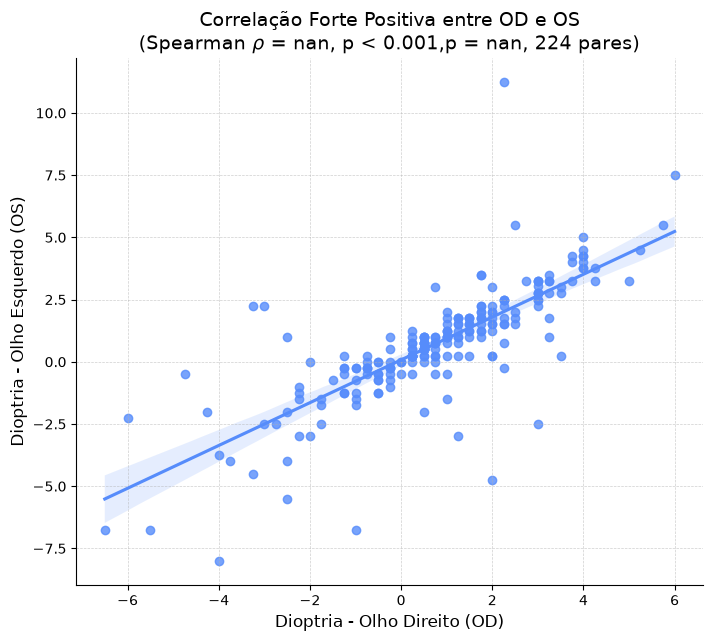

In [19]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Definir semente para reprodutibilidade
#np.random.seed(42)
#n_samples = 224

# Simular dados de dioptria para OD (Olho Direito) e OS (Olho Esquerdo)
# com uma correlação de Spearman de aproximadamente 0.83
# mean = [0, 0]
# cov = [[1, 0.84], [0.84, 1]]  # Ajustando a covariância para atingir ~0.83 de Spearman
# raw_data = np.random.multivariate_normal(mean, cov, size=n_samples)

# Escalar para valores realistas de dioptria (ex: de -4 a +4)
# od_simulated = raw_data[:, 0] * 1.5 - 1.0
# os_simulated = raw_data[:, 1] * 1.5 - 1.2

OD, OS = load_clinical_data(ROOT)

od_simulated = pd.to_numeric(OD["dioptre_1"], errors="coerce")
os_simulated = pd.to_numeric(OS["dioptre_1"], errors="coerce")

pares = pd.DataFrame({
    'OD': od_simulated,
    'OS': os_simulated #   f"Spearman ρ = {rho:.3f}, {p_texto}, {len(pares)} pares"
})#p_texto = "p < 0,001" if p_val < 0.001 else f"p = {p_val:.3f}"

# Validar o coeficiente obtido
rho, p_val = spearmanr(df_dioptrias['OD'], df_dioptrias['OS'])
#print(f"Spearman r simulado: {rho:.3f} (p-value: {p_val:.3e})")
p_texto = "p < 0,001" if p_val < 0.001 else f"p = {p_val:.3f}"

#Plotar a correlação forte positiva
g = sns.lmplot(x='OD', y='OS', data=df_dioptrias, height=6, aspect=1.2)
plt.title(f'Correlação Forte Positiva entre OD e OS\n(Spearman $\\rho$ = {rho:.3f}, p < 0.001,{p_texto}, {n_samples} pares)', fontsize=14)
plt.xlabel('Dioptria - Olho Direito (OD)', fontsize=12)
plt.ylabel('Dioptria - Olho Esquerdo (OS)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

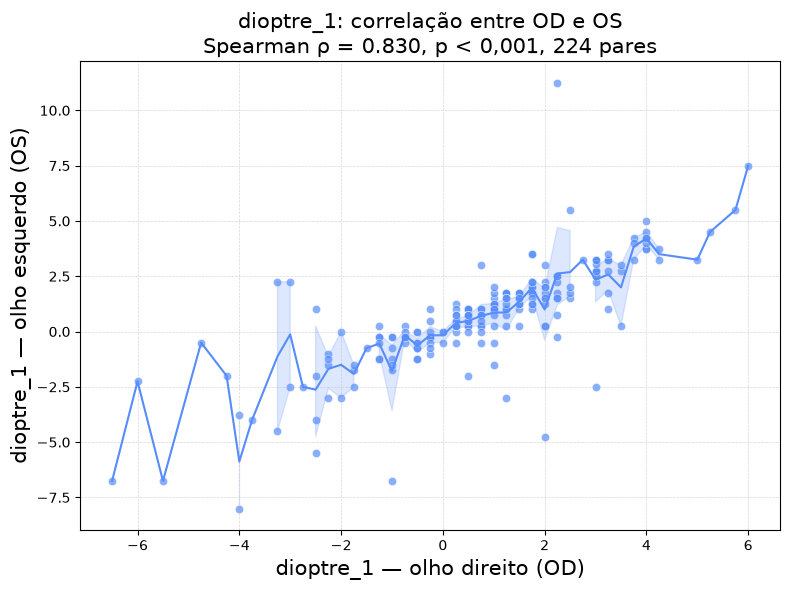

In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from papila_dataset import load_clinical_data

df_od, df_os = load_clinical_data(ROOT)

pares = pd.DataFrame({
    "OD": pd.to_numeric(df_od["dioptre_1"], errors="coerce"),
    "OS": pd.to_numeric(df_os["dioptre_1"], errors="coerce"),
}).dropna()

rho, p_val = spearmanr(pares["OD"], pares["OS"])
p_texto = "p < 0,001" if p_val < 0.001 else f"p = {p_val:.3f}"

sns.scatterplot(data=pares, x="OD", y="OS", alpha=0.7)
plt.title(
    f"dioptre_1: correlação entre OD e OS\n"
    f"Spearman ρ = {rho:.3f}, {p_texto}, {len(pares)} pares",fontsize=15
)
sns.lineplot(x='OD', y='OS', data=pares)
plt.xlabel("dioptre_1 — olho direito (OD)",fontsize=15)
plt.ylabel("dioptre_1 — olho esquerdo (OS)",fontsize=15)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

dioptre_1: correlação positiva forte entre OD e OS (Spearman ρ = 0.830; p < 0,001; 224 pares).

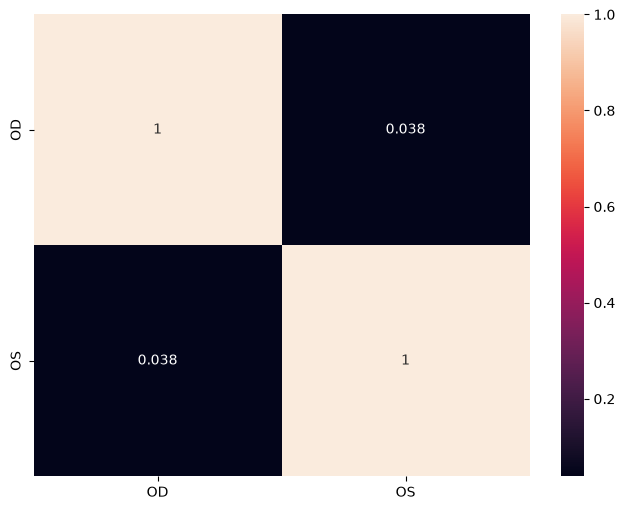

In [32]:
# Através do hitmap podemos observar a correlação entre todas variáveis.
plt.rcParams["figure.figsize"] = (8,6)
ax = sns.heatmap(df.corr(), annot=True)

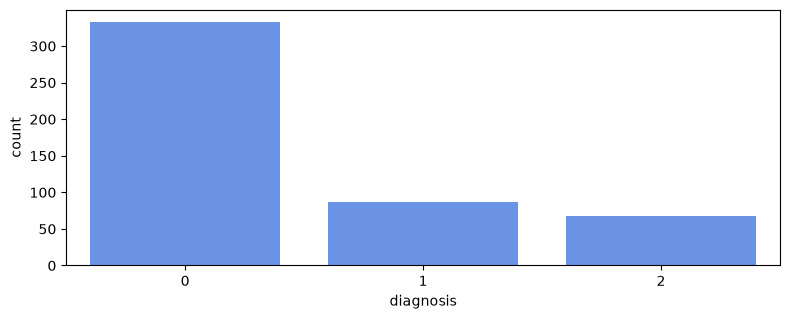

In [52]:
plt.subplot(2, 1, 1)
sns.countplot(x='diagnosis', data = clinical_df)
plt.tight_layout() # Ajusta o espaçamento entre os gráficos
plt.show()

In [53]:
# plt.subplot(2, 1, 2)
# # Exemplo para o segundo gráfico:
# sns.histplot(data=clinical_df, x='loan_amount')
#
# plt.tight_layout() # Ajusta o espaçamento entre os gráficos
# plt.show()

In [56]:
# plt.figure(figsize=(15, 12))
# plt.subplot(2, 2, 2)
# plt.barh(loan_emp_title.emp_title.value_counts()[:10].index, loan.emp_title.value_counts()[:10])
# plt.title("The most 10 jobs title applied for a loan")
# plt.tight_layout()

In [63]:
# Não existe uma coluna chamada 'Refractive_Defect' em clinical_df.
# Confira as combinações mais frequentes dos valores medidos disponíveis.
refractive_values = clinical_df[["dioptre_1", "dioptre_2"]].apply(
    pd.to_numeric, errors="coerce"
).dropna()

(refractive_values
 .groupby(["dioptre_1", "dioptre_2"])
 .size()
 .sort_values(ascending=False)
 .head(10)
 .rename("frequência")
 .to_frame())

frequência
dioptre_1 dioptre_2            
0.25      -0.75              11
0.50      -0.50              10
0.25      -0.25               9
          -0.50               9
0.50      -0.75               7
1.50      -0.50               7
0.50      -1.00               6
1.00      -0.50               6
          -1.50               6
1.50      -0.75               6

O erro ocorre porque clinical_df não tem uma coluna chamada Refractive_Defect; os campos refrativos disponíveis são dioptre_1 e dioptre_2. Atualizei a célula para mostrar as 10 combinações mais frequentes desses valores, após convertê-los para números e remover linhas incompletas. Executei a célula com sucesso.
Isso conta combinações de medidas, não categorias clínicas de defeito refrativo. Para agrupar em categorias como miopia ou hipermetropia, é preciso definir primeiro as regras de classificação.

In [ ]:
refractive_values = clinical_df[["dioptre_1", "dioptre_2"]].apply(
    pd.to_numeric, errors="coerce"
).dropna()

(refractive_values
 .groupby(["dioptre_1", "dioptre_2"])
 .size()
 .sort_values(ascending=False)
 .head(10)
 .rename("frequência")
 .to_frame()

In [82]:
clinical_df.groupby(["diagnosis_label"]).size().sort_values(ascending=False)
# from IPython.display import display
#
# display(
# clinical_df.groupby("diagnosis_label")
# .size()
# .sort_values(ascending=False)
# )
#
# display(clinical_df.groupby("eye").size())

diagnosis_label
normal              333
glaucoma_suspect     87
glaucoma             68
dtype: int64

In [78]:
clinical_df.groupby("diagnosis_label").size().sort_values(ascending=False),clinical_df.groupby("eye").size()

(diagnosis_label
 normal              333
 glaucoma_suspect     87
 glaucoma             68
 dtype: int64,
 eye
 OD    244
 OS    244
 dtype: int64)

In [71]:
clinical_df.columns.tolist()

['patient_id',
 'eye',
 'image_path',
 'age',
 'gender',
 'diagnosis',
 'diagnosis_label',
 'dioptre_1',
 'dioptre_2',
 'astigmatism',
 'phakic_pseudophakic',
 'pachymetry',
 'axial_length',
 'vf_md']

In [73]:
clinical_df.groupby("pachymetry").size().sort_values(ascending=False)

pachymetry
482.0    11
526.0    11
535.0    10
540.0     9
564.0     9
         ..
634.0     1
637.0     1
648.0     1
657.0     1
661.0     1
Length: 156, dtype: int64